<a href="https://colab.research.google.com/github/Dhakshayanikonijeti16/Final-year-project/blob/main/final_year.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

PROJECT: In the ML project totally we have the 8 steps are involved in this project



# Step-1:Define the problem and goal:
PROBLEM STATEMENT : This project explains that how the Sales of the Bigmart is affected by the other variable like Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales

Analysis : In the ML we have to come to know that that it is a supervisied learning because the target variable is given.In the supervisied learning it comes to the category of Regression technique because the target variable is the numerical form

GOAL : The target variable given is here is the Item_Outlet_Sales .


# Step-2: Collect and understand the data:
We have to collect the dataset and check the type of data ,check the outliers present in the data, check the missing values



In [ ]:
import pandas as pd
import numpy as np

In [ ]:
import pandas as pd

In [ ]:
df=pd.read_csv("Train.csv")

In [ ]:
df

,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.300,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.920,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.500,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.200,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.930,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052
...,...,...,...,...,...,...,...,...,...,...,...,...
8518,FDF22,6.865,Low Fat,0.056783,Snack Foods,214.5218,OUT013,1987,High,Tier 3,Supermarket Type1,2778.3834
8519,FDS36,8.380,Regular,0.046982,Baking Goods,108.1570,OUT045,2002,NaN,Tier 2,Supermarket Type1,549.2850
8520,NCJ29,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,OUT035,2004,Small,Tier 2,Supermarket Type1,1193.1136
8521,FDN46,7.210,Regular,0.145221,Snack Foods,103.1332,OUT018,2009,Medium,Tier 3,Supermarket Type2,1845.5976


In [ ]:
# to select the type of the features
df.dtypes

Item_Identifier               object
Item_Weight                  float64
Item_Fat_Content              object
Item_Visibility              float64
Item_Type                     object
Item_MRP                     float64
Outlet_Identifier             object
Outlet_Establishment_Year      int64
Outlet_Size                   object
Outlet_Location_Type          object
Outlet_Type                   object
Item_Outlet_Sales            float64
dtype: object

In [ ]:
#to check the null values present in the dataset or not
df.isnull().sum()

Item_Identifier                 0
Item_Weight                  1463
Item_Fat_Content                0
Item_Visibility                 0
Item_Type                       0
Item_MRP                        0
Outlet_Identifier               0
Outlet_Establishment_Year       0
Outlet_Size                  2410
Outlet_Location_Type            0
Outlet_Type                     0
Item_Outlet_Sales               0
dtype: int64

In [ ]:
# Fill the missing values
# numerical data---->mean or median
# category data------>mode
df['Item_Weight'].fillna(df['Item_Weight'].mean(), inplace=True)
df['Outlet_Size'].fillna(df['Outlet_Size'].mode()[0], inplace=True)

In [ ]:
df.isnull().sum()

Item_Identifier              0
Item_Weight                  0
Item_Fat_Content             0
Item_Visibility              0
Item_Type                    0
Item_MRP                     0
Outlet_Identifier            0
Outlet_Establishment_Year    0
Outlet_Size                  0
Outlet_Location_Type         0
Outlet_Type                  0
Item_Outlet_Sales            0
dtype: int64

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

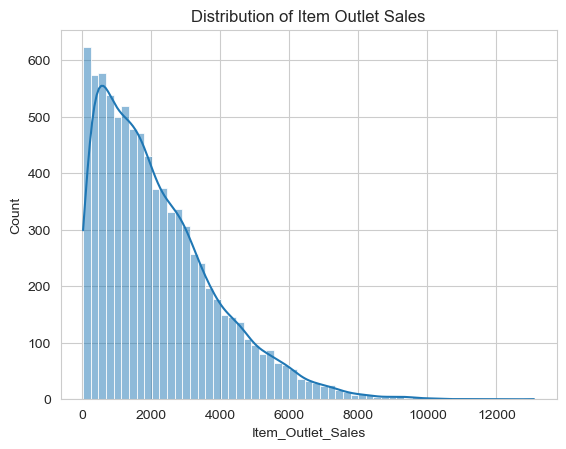

In [ ]:
plt.figure()
sns.histplot(df['Item_Outlet_Sales'], kde=True)
plt.title("Distribution of Item Outlet Sales")
plt.show()

In [ ]:
# Outlet age
df['Outlet_Age'] = 2026 - df['Outlet_Establishment_Year']

# Visibility fix
df['Item_Visibility'] = df['Item_Visibility'].replace(0, np.nan)
df['Item_Visibility'].fillna(df['Item_Visibility'].mean(), inplace=True)

# Visibility ratio
df['Item_Visibility_Mean'] = df.groupby('Item_Type')['Item_Visibility'].transform('mean')
df['Item_Visibility_Ratio'] = df['Item_Visibility'] / df['Item_Visibility_Mean']

# MRP interaction
df['MRP_Visibility'] = df['Item_MRP'] * df['Item_Visibility']

# Log transform target
df['Item_Outlet_Sales'] = np.log1p(df['Item_Outlet_Sales'])

In [ ]:
df.drop(['Item_Identifier'], axis=1, inplace=True)

In [ ]:
df.drop(['Outlet_Identifier'],axis=1,inplace=True)

In [ ]:
df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({
    'low fat': 'Low Fat',
    'LF': 'Low Fat',
    'reg': 'Regular'
})

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

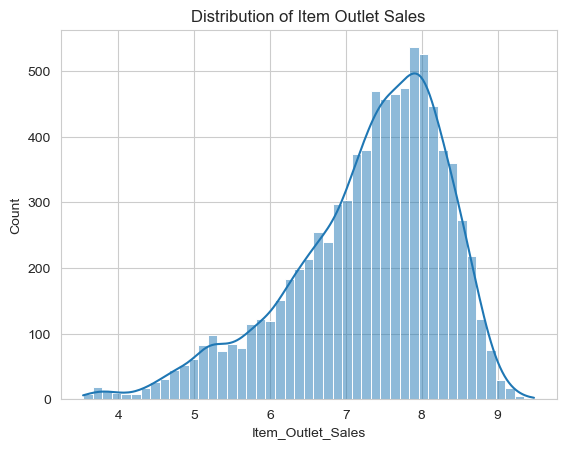

In [ ]:
plt.figure()
sns.histplot(df['Item_Outlet_Sales'], kde=True)
plt.title("Distribution of Item Outlet Sales")
plt.show()

In [ ]:
df

,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Outlet_Age,Item_Visibility_Mean,Item_Visibility_Ratio,MRP_Visibility
0,9.300,Low Fat,0.016047,Dairy,249.8092,1999,Medium,Tier 1,Supermarket Type1,8.225808,27,0.076354,0.210169,4.008763
1,5.920,Regular,0.019278,Soft Drinks,48.2692,2009,Medium,Tier 3,Supermarket Type2,6.096776,17,0.069357,0.277955,0.930544
2,17.500,Low Fat,0.016760,Meat,141.6180,1999,Medium,Tier 1,Supermarket Type1,7.648868,27,0.065601,0.255487,2.373528
3,19.200,Regular,0.070482,Fruits and Vegetables,182.0950,1998,Medium,Tier 3,Grocery Store,6.597664,28,0.073490,0.959065,12.834391
4,8.930,Low Fat,0.070482,Household,53.8614,1987,High,Tier 3,Supermarket Type1,6.903451,39,0.065272,1.079811,3.796251
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8518,6.865,Low Fat,0.056783,Snack Foods,214.5218,1987,High,Tier 3,Supermarket Type1,7.929984,39,0.070844,0.801525,12.181275
8519,8.380,Regular,0.046982,Baking Goods,108.1570,2002,Medium,Tier 2,Supermarket Type1,6.310436,24,0.074064,0.634350,5.081479
8520,10.600,Low Fat,0.035186,Health and Hygiene,85.1224,2004,Small,Tier 2,Supermarket Type1,7.085159,22,0.059689,0.589495,2.995140
8521,7.210,Regular,0.145221,Snack Foods,103.1332,2009,Medium,Tier 3,Supermarket Type2,7.521100,17,0.070844,2.049860,14.977070


# Step-3 datapreprocessing:

ENCODING THE CATEGORIAL VARIABLES: firstly we have to convert the categorial data into the numerical number.We have different types of categorial data like ordinal,nominal,binary.We have different methods for the different types of data .


In [ ]:
df = pd.get_dummies(df, drop_first=True)

In [ ]:
df

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales,Outlet_Age,Item_Visibility_Mean,Item_Visibility_Ratio,MRP_Visibility,Item_Fat_Content_Regular,...,Item_Type_Snack Foods,Item_Type_Soft Drinks,Item_Type_Starchy Foods,Outlet_Size_Medium,Outlet_Size_Small,Outlet_Location_Type_Tier 2,Outlet_Location_Type_Tier 3,Outlet_Type_Supermarket Type1,Outlet_Type_Supermarket Type2,Outlet_Type_Supermarket Type3
0,9.300,0.016047,249.8092,1999,8.225808,27,0.076354,0.210169,4.008763,False,...,False,False,False,True,False,False,False,True,False,False
1,5.920,0.019278,48.2692,2009,6.096776,17,0.069357,0.277955,0.930544,True,...,False,True,False,True,False,False,True,False,True,False
2,17.500,0.016760,141.6180,1999,7.648868,27,0.065601,0.255487,2.373528,False,...,False,False,False,True,False,False,False,True,False,False
3,19.200,0.070482,182.0950,1998,6.597664,28,0.073490,0.959065,12.834391,True,...,False,False,False,True,False,False,True,False,False,False
4,8.930,0.070482,53.8614,1987,6.903451,39,0.065272,1.079811,3.796251,False,...,False,False,False,False,False,False,True,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8518,6.865,0.056783,214.5218,1987,7.929984,39,0.070844,0.801525,12.181275,False,...,True,False,False,False,False,False,True,True,False,False
8519,8.380,0.046982,108.1570,2002,6.310436,24,0.074064,0.634350,5.081479,True,...,False,False,False,True,False,True,False,True,False,False
8520,10.600,0.035186,85.1224,2004,7.085159,22,0.059689,0.589495,2.995140,False,...,False,False,False,False,True,True,False,True,False,False
8521,7.210,0.145221,103.1332,2009,7.521100,17,0.070844,2.049860,14.977070,True,...,True,False,False,True,False,False,True,False,True,False


In [ ]:
df.astype(int)

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales,Outlet_Age,Item_Visibility_Mean,Item_Visibility_Ratio,MRP_Visibility,Item_Fat_Content_Regular,...,Item_Type_Snack Foods,Item_Type_Soft Drinks,Item_Type_Starchy Foods,Outlet_Size_Medium,Outlet_Size_Small,Outlet_Location_Type_Tier 2,Outlet_Location_Type_Tier 3,Outlet_Type_Supermarket Type1,Outlet_Type_Supermarket Type2,Outlet_Type_Supermarket Type3
0,9,0,249,1999,8,27,0,0,4,0,...,0,0,0,1,0,0,0,1,0,0
1,5,0,48,2009,6,17,0,0,0,1,...,0,1,0,1,0,0,1,0,1,0
2,17,0,141,1999,7,27,0,0,2,0,...,0,0,0,1,0,0,0,1,0,0
3,19,0,182,1998,6,28,0,0,12,1,...,0,0,0,1,0,0,1,0,0,0
4,8,0,53,1987,6,39,0,1,3,0,...,0,0,0,0,0,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8518,6,0,214,1987,7,39,0,0,12,0,...,1,0,0,0,0,0,1,1,0,0
8519,8,0,108,2002,6,24,0,0,5,1,...,0,0,0,1,0,1,0,1,0,0
8520,10,0,85,2004,7,22,0,0,2,0,...,0,0,0,0,1,1,0,1,0,0
8521,7,0,103,2009,7,17,0,2,14,1,...,1,0,0,1,0,0,1,0,1,0



# Step-4: Feature Engineering & EDA

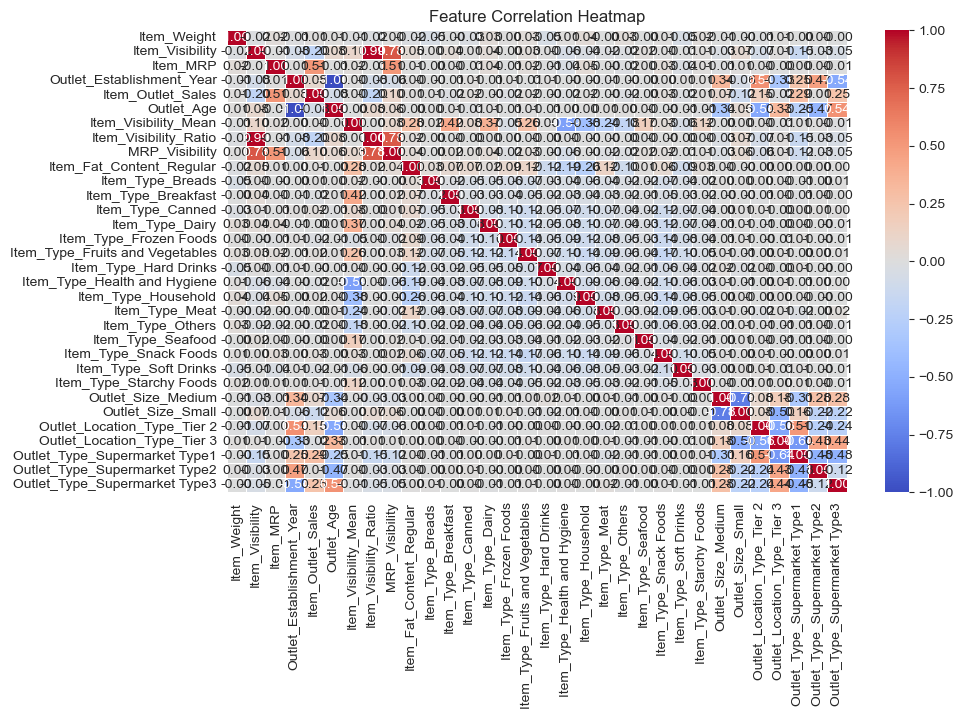

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
correlation = df.corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation, annot=True,cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

In [ ]:
# import pandas as pd
# from sklearn.preprocessing import StandardScaler


# # Select numerical columns
# num_cols = df.select_dtypes(include=['int64', 'float64']).columns

# # Initialize scaler
# scaler = StandardScaler()

# # Fit and transform
# df[num_cols] = scaler.fit_transform(df[num_cols])

# # View result
# df

# Step-5 Model Selection:
Here the target variable given here is maths score and so it in the numerical form we have to select the regression model because the target variable is numerical

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('Item_Outlet_Sales', axis=1)
y = df['Item_Outlet_Sales']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Step 1: Create model
model = LinearRegression()

# Step 2: Train model
model.fit(X_train, y_train)

# Step 3: Predictions
y_pred = model.predict(X_test)

# Step 4: Evaluation metrics
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

# Step 5: Print results
print("R2 Score:", r2)
print("Mean Squared Error:", mse)
print("Root Mean Squared Error:", rmse)

R2 Score: 0.7301174971673371
Mean Squared Error: 0.2837393753583014
Root Mean Squared Error: 0.5326719209403677


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Step 1: Create model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Step 2: Train model
rf_model.fit(X_train, y_train)

# Step 3: Predictions
y_pred_rf = rf_model.predict(X_test)

# Step 4: Evaluation
r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)

# Step 5: Print results
print("Random Forest R2 Score:", r2_rf)
print("Random Forest MSE:", mse_rf)
print("Random Forest RMSE:", rmse_rf)

Random Forest R2 Score: 0.7145151546330069
Random Forest MSE: 0.30014280603035953
Random Forest RMSE: 0.5478529054685751


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Step 1: Define model
rf = RandomForestRegressor(random_state=42)

# Step 2: Define parameter grid
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2]
}

# Step 3: Grid Search
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    cv=5,
    scoring='r2',
    n_jobs=-1,
    verbose=2
)

grid_search.fit(X_train, y_train)

# Step 4: Best model
best_rf = grid_search.best_estimator_

# Step 5: Predictions
y_pred = best_rf.predict(X_test)

# Step 6: Evaluation
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Best Parameters:", grid_search.best_params_)
print("R2 Score:", r2)
print("MSE:", mse)
print("RMSE:", rmse)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters: {'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 200}
R2 Score: 0.7363313396968658
MSE: 0.2772064887154185
RMSE: 0.5265040253553799


In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_dist,
    n_iter=10,   # number of combinations to try
    cv=5,
    scoring='r2',
    n_jobs=-1,
    random_state=42,
    verbose=2
)

random_search.fit(X_train, y_train)

best_rf = random_search.best_estimator_

y_pred = best_rf.predict(X_test)

r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Best Parameters:", random_search.best_params_)
print("R2 Score:", r2)
print("MSE:", mse)
print("RMSE:", rmse)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_depth': 10}
R2 Score: 0.7390705887026069
MSE: 0.27432659545193505
RMSE: 0.523761964495261


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Step 1: Create model
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

# Step 2: Train
xgb_model.fit(X_train, y_train)

# Step 3: Predict
y_pred_xgb = xgb_model.predict(X_test)

# Step 4: Evaluate
r2_xgb = r2_score(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)

print("XGBoost R2 Score:", r2_xgb)
print("XGBoost MSE:", mse_xgb)
print("XGBoost RMSE:", rmse_xgb)

XGBoost R2 Score: 0.7347330799976778
XGBoost MSE: 0.2788868096104308
XGBoost RMSE: 0.5280973486114381


In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Step 1: Create model
dt_model = DecisionTreeRegressor(
    random_state=42
)

# Step 2: Train
dt_model.fit(X_train, y_train)

# Step 3: Predict
y_pred_dt = dt_model.predict(X_test)

# Step 4: Evaluate
r2_dt = r2_score(y_test, y_pred_dt)
mse_dt = mean_squared_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mse_dt)

print("Decision Tree R2 Score:", r2_dt)
print("Decision Tree MSE:", mse_dt)
print("Decision Tree RMSE:", rmse_dt)

Decision Tree R2 Score: 0.4906945507700011
Decision Tree MSE: 0.5354552759602222
Decision Tree RMSE: 0.7317480959730761


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Step 1: Create model
ridge_model = Ridge(alpha=1.0)

# Step 2: Train
ridge_model.fit(X_train, y_train)

# Step 3: Predict
y_pred_ridge = ridge_model.predict(X_test)

# Step 4: Evaluate
r2_ridge = r2_score(y_test, y_pred_ridge)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)

print("Ridge R2 Score:", r2_ridge)
print("Ridge MSE:", mse_ridge)
print("Ridge RMSE:", rmse_ridge)

Ridge R2 Score: 0.7301203315952942
Ridge MSE: 0.2837363953992095
Ridge RMSE: 0.5326691237524562


In [ ]:
# Store results in lists
models = [
    "Linear Regression",
    "Random Forest",
    "Decision Tree",
    "XGBoost",
    "Ridge Regression"
]

mse_values = [
    mse,        # Linear Regression
    mse_rf,     # Random Forest
        # Decision Tree
    mse_xgb,
     mse_dt,# XGBoost
    mse_ridge   # Ridge
]

rmse_values = [
    rmse,
    rmse_rf,

    rmse_xgb,
    rmse_dt,
    rmse_ridge
]

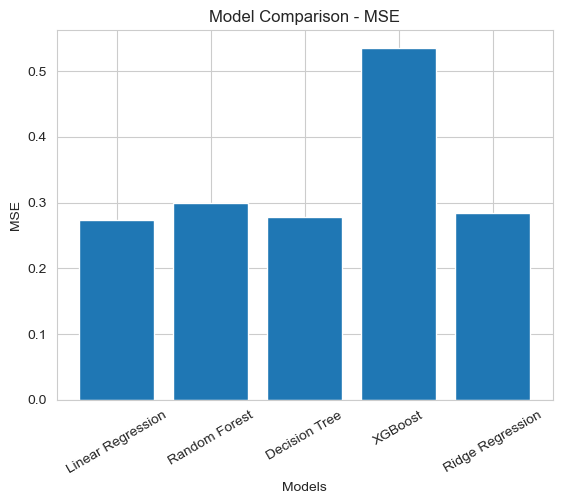

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.bar(models, mse_values)
plt.title("Model Comparison - MSE")
plt.xlabel("Models")
plt.ylabel("MSE")
plt.xticks(rotation=30)
plt.show()

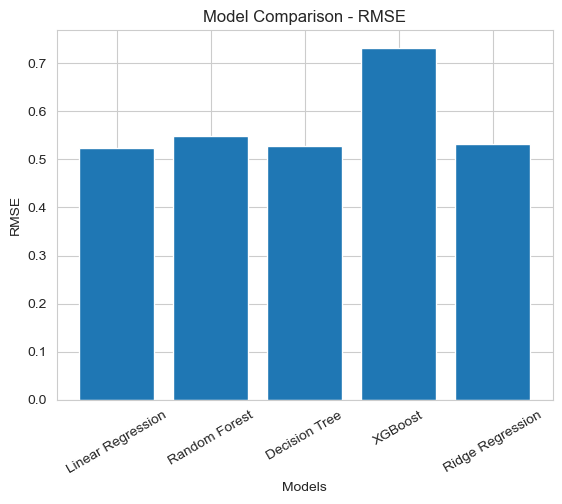

In [ ]:
plt.figure()
plt.bar(models, rmse_values)
plt.title("Model Comparison - RMSE")
plt.xlabel("Models")
plt.ylabel("RMSE")
plt.xticks(rotation=30)
plt.show()

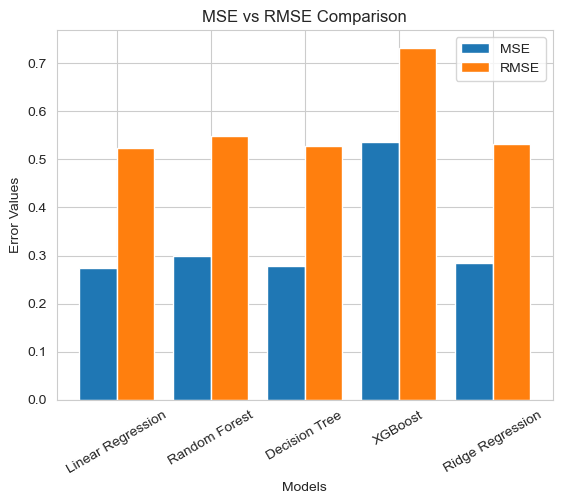

In [ ]:
import numpy as np

x = np.arange(len(models))

plt.figure()

plt.bar(x - 0.2, mse_values, width=0.4, label="MSE")
plt.bar(x + 0.2, rmse_values, width=0.4, label="RMSE")

plt.xticks(x, models, rotation=30)
plt.xlabel("Models")
plt.ylabel("Error Values")
plt.title("MSE vs RMSE Comparison")
plt.legend()

plt.show()

# Step-6: XGBRegressor Model:
from the above model the best model is the XGBRegressor which is having the lowest meansqured error and highest r2 score

In [ ]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=8,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.3,
    reg_lambda=1
)

xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0.1, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=3, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1200,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error

y_pred = xgb.predict(X_test)

print("R2 Score:", r2_score(y_test, y_pred))

# Convert back to original scale
y_pred_actual = np.expm1(y_pred)
y_test_actual = np.expm1(y_test)

rmse = np.sqrt(mean_squared_error(y_test_actual, y_pred_actual))
print("RMSE:", rmse)

R2 Score: 0.7167615900801584
RMSE: 1116.757037116142


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(xgb, X, y, cv=5, scoring='r2')
print("CV Score:", scores.mean())

CV Score: 0.6939496455833477


In [ ]:
importance = xgb.feature_importances_

feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

top_features = feat_imp.head(20)['Feature'].tolist()

X = X[top_features]

In [ ]:
from sklearn.model_selection import train_test_split

y = df['Item_Outlet_Sales']   # keep target same

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [ ]:
from xgboost import XGBRegressor

xgb = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.02,
    max_depth=8,
    min_child_weight=4,
    subsample=0.8,
    colsample_bytree=0.8,
    gamma=0.1,
    reg_alpha=0.3,
    reg_lambda=1
)

xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=0.1, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.02, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
             max_leaves=None, min_child_weight=4, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=1000,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Step 1: Create model
xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42
)

# Step 2: Train
xgb_model.fit(X_train, y_train)

# Step 3: Predict
y_pred_xgb = xgb_model.predict(X_test)

# Step 4: Evaluate
r2_xgb = r2_score(y_test, y_pred_xgb)
mse_xgb = mean_squared_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mse_xgb)

print("XGBoost R2 Score:", r2_xgb)
print("XGBoost MSE:", mse_xgb)
print("XGBoost RMSE:", rmse_xgb)

XGBoost R2 Score: 0.7353354899995217
XGBoost MSE: 0.27825346941297924
XGBoost RMSE: 0.5274973643659078


# Step-7 Model Evaluation:

In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(xgb, X, y, cv=5, scoring='r2')
print("CV Score:", scores.mean())

CV Score: 0.7007802096469388


In [ ]:
df.astype(int)

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales,Outlet_Age,Item_Visibility_Mean,Item_Visibility_Ratio,MRP_Visibility,Item_Fat_Content_Regular,...,Item_Type_Snack Foods,Item_Type_Soft Drinks,Item_Type_Starchy Foods,Outlet_Size_Medium,Outlet_Size_Small,Outlet_Location_Type_Tier 2,Outlet_Location_Type_Tier 3,Outlet_Type_Supermarket Type1,Outlet_Type_Supermarket Type2,Outlet_Type_Supermarket Type3
0,9,0,249,1999,8,27,0,0,4,0,...,0,0,0,1,0,0,0,1,0,0
1,5,0,48,2009,6,17,0,0,0,1,...,0,1,0,1,0,0,1,0,1,0
2,17,0,141,1999,7,27,0,0,2,0,...,0,0,0,1,0,0,0,1,0,0
3,19,0,182,1998,6,28,0,0,12,1,...,0,0,0,1,0,0,1,0,0,0
4,8,0,53,1987,6,39,0,1,3,0,...,0,0,0,0,0,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8518,6,0,214,1987,7,39,0,0,12,0,...,1,0,0,0,0,0,1,1,0,0
8519,8,0,108,2002,6,24,0,0,5,1,...,0,0,0,1,0,1,0,1,0,0
8520,10,0,85,2004,7,22,0,0,2,0,...,0,0,0,0,1,1,0,1,0,0
8521,7,0,103,2009,7,17,0,2,14,1,...,1,0,0,1,0,0,1,0,1,0


In [ ]:
xgb = XGBRegressor(
    n_estimators=2000,
    learning_rate=0.015,
    max_depth=7,
    min_child_weight=5,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=0.5,
    reg_lambda=1.5
)

In [ ]:
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.015, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=2000,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
import pandas as pd

importance = xgb.feature_importances_

feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

print(feat_imp.head(15))

                          Feature  Importance
1   Outlet_Type_Supermarket Type3    0.333988
0   Outlet_Type_Supermarket Type2    0.271612
2   Outlet_Type_Supermarket Type1    0.125700
6               Outlet_Size_Small    0.039549
3                      Outlet_Age    0.036655
5                        Item_MRP    0.035665
7              Outlet_Size_Medium    0.026758
4       Outlet_Establishment_Year    0.023544
8     Outlet_Location_Type_Tier 3    0.017996
9                  MRP_Visibility    0.011314
11            Item_Type_Breakfast    0.010498
10                Item_Visibility    0.010371
12          Item_Visibility_Ratio    0.010081
15          Item_Type_Soft Drinks    0.007303
16                    Item_Weight    0.007106


In [ ]:
top_features = feat_imp.head(25)['Feature'].tolist()

X_new = X[top_features]

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_new, y, test_size=0.2, random_state=42
)

In [ ]:
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.015, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=2000,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import r2_score

y_pred = xgb.predict(X_test)
print("R2 Score:", r2_score(y_test, y_pred))

R2 Score: 0.7187754572204526


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(xgb, X_new, y, cv=5, scoring='r2')
print("CV Score:", scores.mean())

CV Score: 0.6961403416562539


In [ ]:
for k in [15, 20, 25, 30]:
    top_features = feat_imp.head(k)['Feature'].tolist()
    X_temp = X[top_features]

    scores = cross_val_score(xgb, X_temp, y, cv=5, scoring='r2')
    print(f"Top {k} features → CV:", scores.mean())

Top 15 features → CV: 0.6969319791200721
Top 20 features → CV: 0.6961403416562539
Top 25 features → CV: 0.6961403416562539
Top 30 features → CV: 0.6961403416562539


In [ ]:
cols_to_drop = [
    'Item_Visibility_Ratio',
    'MRP_Visibility',
    'Item_Weight'
]

# Drop all Item_Type columns
cols_to_drop += [col for col in X.columns if 'Item_Type_' in col]

X_new = X.drop(cols_to_drop, axis=1)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_new, y, test_size=0.2, random_state=42
)

In [ ]:
xgb.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.015, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=7,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=2000,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import r2_score

y_pred = xgb.predict(X_test)
print("R2:", r2_score(y_test, y_pred))



R2: 0.72656162260844


In [ ]:
df.astype(int)

,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales,Outlet_Age,Item_Visibility_Mean,Item_Visibility_Ratio,MRP_Visibility,Item_Fat_Content_Regular,...,Item_Type_Snack Foods,Item_Type_Soft Drinks,Item_Type_Starchy Foods,Outlet_Size_Medium,Outlet_Size_Small,Outlet_Location_Type_Tier 2,Outlet_Location_Type_Tier 3,Outlet_Type_Supermarket Type1,Outlet_Type_Supermarket Type2,Outlet_Type_Supermarket Type3
0,9,0,249,1999,8,27,0,0,4,0,...,0,0,0,1,0,0,0,1,0,0
1,5,0,48,2009,6,17,0,0,0,1,...,0,1,0,1,0,0,1,0,1,0
2,17,0,141,1999,7,27,0,0,2,0,...,0,0,0,1,0,0,0,1,0,0
3,19,0,182,1998,6,28,0,0,12,1,...,0,0,0,1,0,0,1,0,0,0
4,8,0,53,1987,6,39,0,1,3,0,...,0,0,0,0,0,0,1,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8518,6,0,214,1987,7,39,0,0,12,0,...,1,0,0,0,0,0,1,1,0,0
8519,8,0,108,2002,6,24,0,0,5,1,...,0,0,0,1,0,1,0,1,0,0
8520,10,0,85,2004,7,22,0,0,2,0,...,0,0,0,0,1,1,0,1,0,0
8521,7,0,103,2009,7,17,0,2,14,1,...,1,0,0,1,0,0,1,0,1,0


In [ ]:
from xgboost import XGBRegressor

# Final model
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=6,
    min_child_weight=5,
    subsample=0.7,
    colsample_bytree=0.7,
    reg_alpha=0.5,
    reg_lambda=1,
    random_state=42
)

# Train model
xgb_model.fit(X_train, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.7, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.03, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
             max_leaves=None, min_child_weight=5, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=500,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Predictions
y_pred = xgb_model.predict(X_test)

# Metrics
r2 = r2_score(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R2 Score:", r2)
print("MSE:", mse)
print("RMSE:", rmse)

R2 Score: 0.7428338517456837
MSE: 0.2703701110783865
RMSE: 0.519971259858068


# Step-8: conclusion

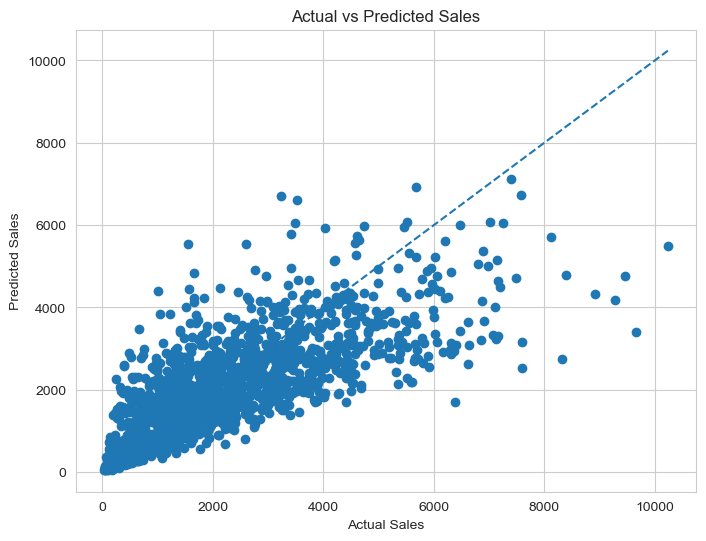

In [ ]:
import matplotlib.pyplot as plt

# If you used log transform, convert back
import numpy as np
y_test_actual = np.expm1(y_test)
y_pred_actual = np.expm1(y_pred)

plt.figure(figsize=(8,6))
plt.scatter(y_test_actual, y_pred_actual)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales")

# Perfect prediction line
plt.plot([y_test_actual.min(), y_test_actual.max()],
         [y_test_actual.min(), y_test_actual.max()],
         linestyle='--')

plt.show()

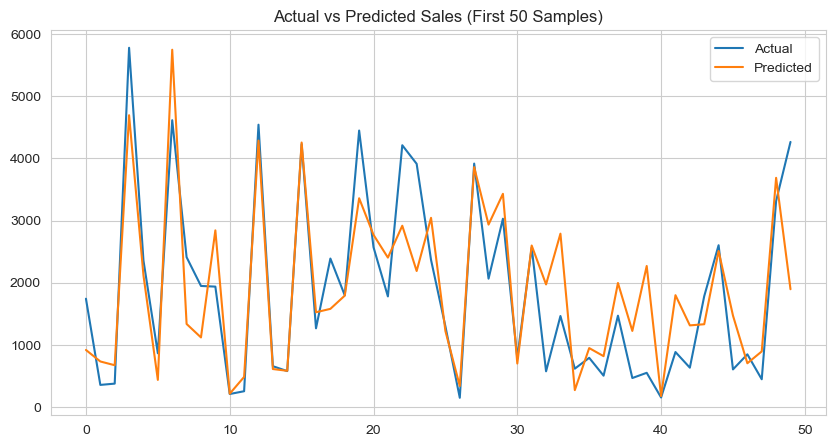

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(y_test_actual.values[:50], label='Actual')
plt.plot(y_pred_actual[:50], label='Predicted')

plt.legend()
plt.title("Actual vs Predicted Sales (First 50 Samples)")
plt.show()

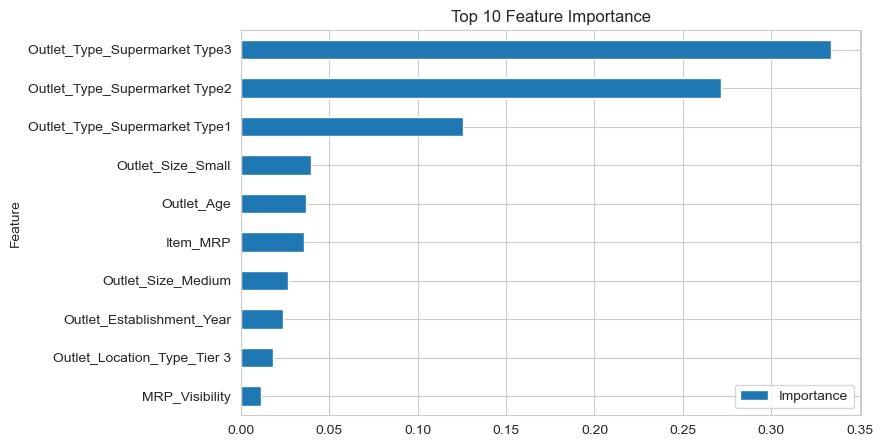

In [ ]:
import matplotlib.pyplot as plt

feat_imp.head(10).plot(
    x='Feature',
    y='Importance',
    kind='barh',
    figsize=(8,5)
)

plt.title("Top 10 Feature Importance")
plt.gca().invert_yaxis()
plt.show()